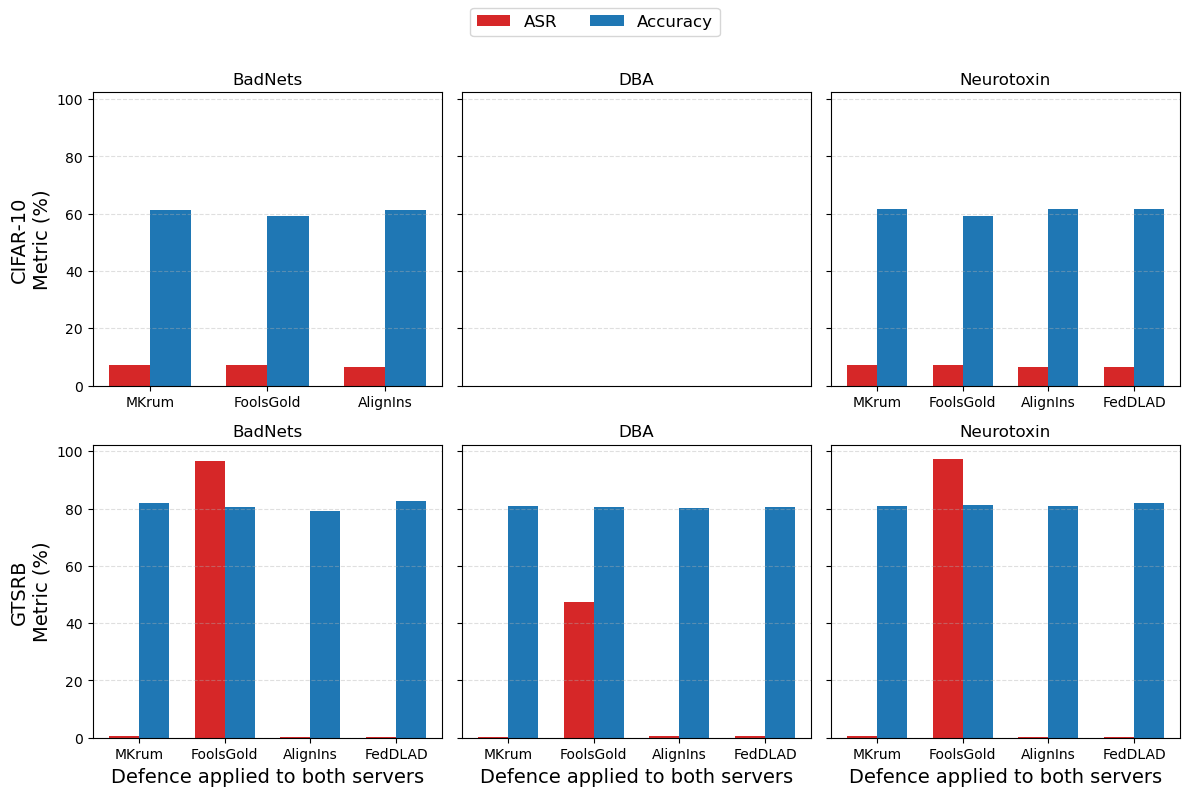

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def preprocess(df, rnd=50):
    df = df[df["defense"] == df["defense_server"]]
    df = df[df["defense_start_round"] == rnd]
    return df

# ---- Name mappings ----
attack_map = {
    "badnet": "BadNets",
    "DBA"   : "DBA",
    "neurotoxin": "Neurotoxin",
}

defense_map = {
    "mkrum": "MKrum",
    "foolsgold": "FoolsGold",
    "alignins": "AlignIns",
    "feddlad": "FedDLAD",
    "avg": "FedAvg"
}
defense_order = ["mkrum", "foolsgold", "alignins", "feddlad"]

attacks = ["badnet", "DBA", "neurotoxin"]

color_asr = "#d62728"   # red
color_acc = "#1f77b4"   # blue

def plot_panel(ax, df, attack):
    sub = df[df["attack"] == attack]
    grouped = sub.groupby("defense_server").mean(numeric_only=True)

    defenses = [d for d in defense_order if d in grouped.index]

    asr = [grouped.loc[d]["asr"] for d in defenses]
    acc = [grouped.loc[d]["main_task"] for d in defenses]

    x = np.arange(len(defenses))
    width = 0.35

    ax.bar(x - width/2, asr, width, color=color_asr, label="ASR")
    ax.bar(x + width/2, acc, width, color=color_acc, label="Accuracy")

    # Apply readable labels
    ax.set_title(attack_map[attack])
    ax.set_xticks(x)
    ax.set_xticklabels([defense_map.get(d, d) for d in defenses])

    # ax.set_xlabel("Defence applied to both servers", fontsize=14)
    ax.grid(axis="y", linestyle="--", alpha=0.4)


# Load data
# df_mnist = preprocess(pd.read_csv("all_start_rounds_mnist.csv"))
df_cifar10  = preprocess(pd.read_csv("all_start_rounds_cifar10.csv"))
df_gtsrb  = preprocess(pd.read_csv("all_start_rounds_gtsrb.csv"))

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharey=True)

# Row 0: CIFAR-10
for j, attack in enumerate(attacks):
    plot_panel(axes[0, j], df_cifar10, attack)

# Row 1: GTSRB
for j, attack in enumerate(attacks):
    plot_panel(axes[1, j], df_gtsrb, attack)

# Row labels
axes[1, 0].set_ylabel("GTSRB\nMetric (%)", fontsize=14)
axes[0, 0].set_ylabel("CIFAR-10\nMetric (%)", fontsize=14)
axes[1, 0].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 1].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 2].set_xlabel("Defence applied to both servers", fontsize=14)

# Shared legend (clean version)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

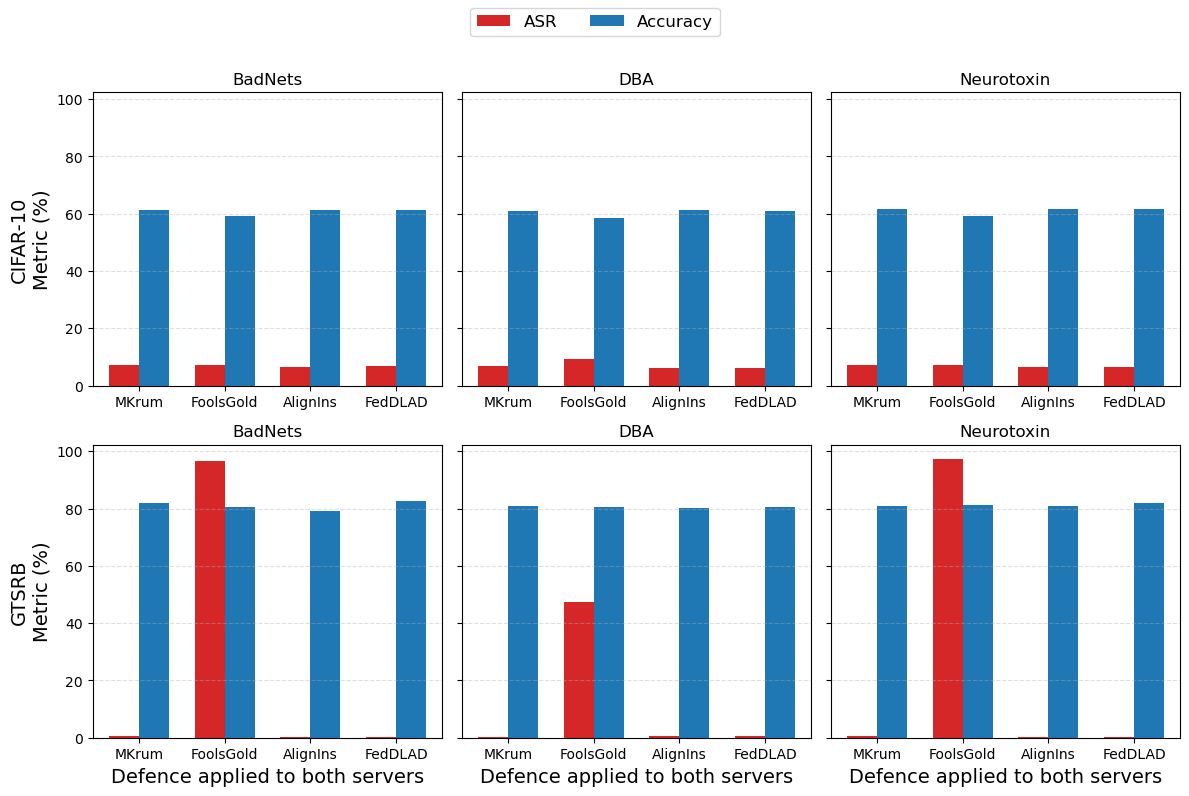

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def preprocess(df, rnd=50):
    df = df[df["defense"] == df["defense_server"]]
    df = df[df["defense_start_round"] == rnd]
    return df

# ---- Name mappings ----
attack_map = {
    "badnet": "BadNets",
    "DBA"   : "DBA",
    "neurotoxin": "Neurotoxin",
}

defense_map = {
    "mkrum": "MKrum",
    "foolsgold": "FoolsGold",
    "alignins": "AlignIns",
    "feddlad": "FedDLAD",
    "avg": "FedAvg"
}
defense_order = ["mkrum", "foolsgold", "alignins", "feddlad"]

attacks = ["badnet", "DBA", "neurotoxin"]

color_asr = "#d62728"   # red
color_acc = "#1f77b4"   # blue

def plot_panel(ax, df, attack):
    sub = df[df["attack"] == attack]
    grouped = sub.groupby("defense_server").mean(numeric_only=True)

    defenses = [d for d in defense_order if d in grouped.index]

    asr = [grouped.loc[d]["asr"] for d in defenses]
    acc = [grouped.loc[d]["main_task"] for d in defenses]

    x = np.arange(len(defenses))
    width = 0.35

    ax.bar(x - width/2, asr, width, color=color_asr, label="ASR")
    ax.bar(x + width/2, acc, width, color=color_acc, label="Accuracy")

    # Apply readable labels
    ax.set_title(attack_map[attack])
    ax.set_xticks(x)
    ax.set_xticklabels([defense_map.get(d, d) for d in defenses])

    # ax.set_xlabel("Defence applied to both servers", fontsize=14)
    ax.grid(axis="y", linestyle="--", alpha=0.4)


# Load data
# df_mnist = preprocess(pd.read_csv("all_start_rounds_mnist.csv"))
df_cifar10  = preprocess(pd.read_csv("all_start_rounds_cifar10.csv"))
df_gtsrb  = preprocess(pd.read_csv("all_start_rounds_gtsrb.csv"))

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharey=True)

# Row 0: CIFAR-10
for j, attack in enumerate(attacks):
    plot_panel(axes[0, j], df_cifar10, attack)

# Row 1: GTSRB
for j, attack in enumerate(attacks):
    plot_panel(axes[1, j], df_gtsrb, attack)

# Row labels
axes[1, 0].set_ylabel("GTSRB\nMetric (%)", fontsize=14)
axes[0, 0].set_ylabel("CIFAR-10\nMetric (%)", fontsize=14)
axes[1, 0].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 1].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 2].set_xlabel("Defence applied to both servers", fontsize=14)

# Shared legend (clean version)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

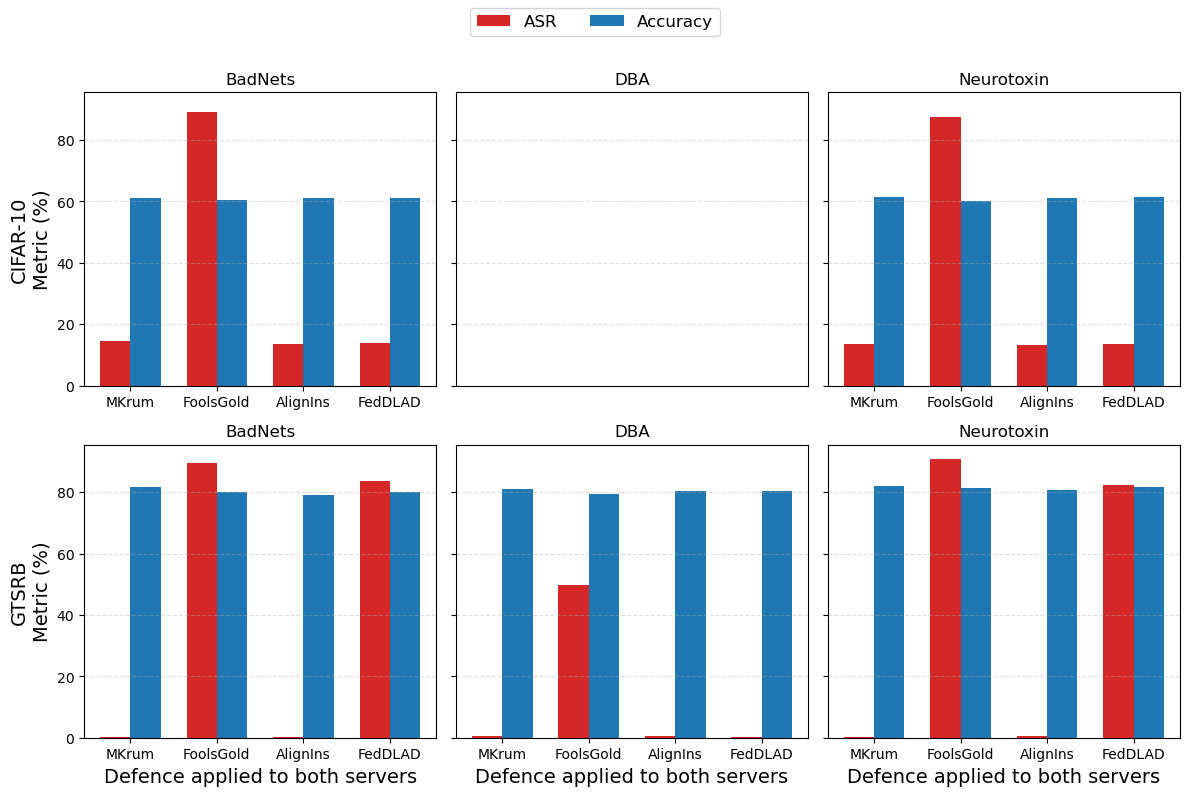

In [3]:
# Load data
df_mnist50 = preprocess(pd.read_csv("all_start_rounds_mnist.csv"), rnd=50)
df_mnist = preprocess(pd.read_csv("all_start_rounds_mnist.csv"), rnd=100)
df_mnist = pd.concat([df_mnist50[df_mnist50["attack"].isin(["badnet", "neurotoxin"])], df_mnist], ignore_index=True)
df_cifar10  = preprocess(pd.read_csv("all_start_rounds_cifar10.csv"), rnd=100)
df_gtsrb  = preprocess(pd.read_csv("all_start_rounds_gtsrb.csv"), rnd=100)

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharey=True)

attacks = ["badnet", "DBA", "neurotoxin"]

# Row 0: CIFAR-10
for j, attack in enumerate(attacks):
    plot_panel(axes[0, j], df_cifar10, attack)

# Row 1: GTSRB
for j, attack in enumerate(attacks):
    plot_panel(axes[1, j], df_gtsrb, attack)

# Row labels
axes[0, 0].set_ylabel("CIFAR-10\nMetric (%)", fontsize=14)
axes[1, 0].set_ylabel("GTSRB\nMetric (%)", fontsize=14)
axes[1, 0].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 1].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 2].set_xlabel("Defence applied to both servers", fontsize=14)

# Shared legend (clean version)
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

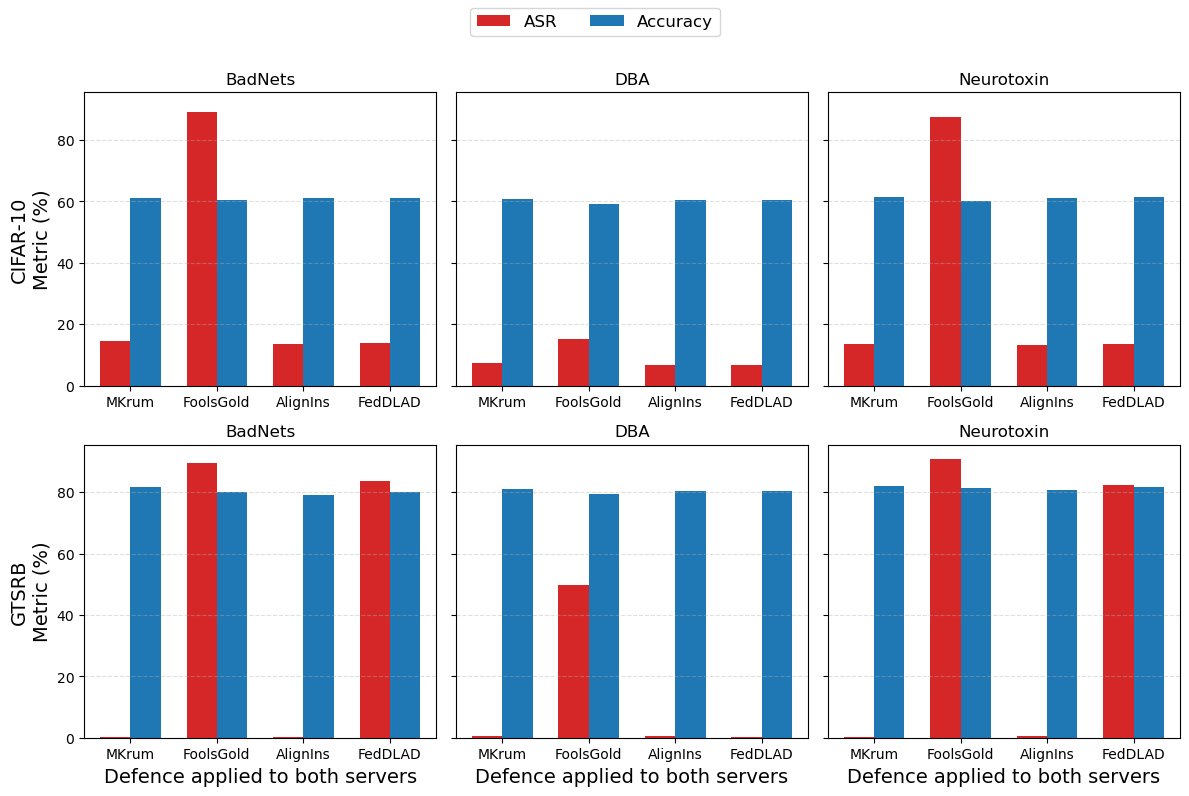

In [5]:
# Load data
df_mnist50 = preprocess(pd.read_csv("all_start_rounds_mnist.csv"), rnd=50)
df_mnist = preprocess(pd.read_csv("all_start_rounds_mnist.csv"), rnd=100)
df_mnist = pd.concat([df_mnist50[df_mnist50["attack"].isin(["badnet", "neurotoxin"])], df_mnist], ignore_index=True)
df_cifar10  = preprocess(pd.read_csv("all_start_rounds_cifar10.csv"), rnd=100)
df_gtsrb  = preprocess(pd.read_csv("all_start_rounds_gtsrb.csv"), rnd=100)

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharey=True)

attacks = ["badnet", "DBA", "neurotoxin"]

# Row 0: CIFAR-10
for j, attack in enumerate(attacks):
    plot_panel(axes[0, j], df_cifar10, attack)

# Row 1: GTSRB
for j, attack in enumerate(attacks):
    plot_panel(axes[1, j], df_gtsrb, attack)

# Row labels
axes[0, 0].set_ylabel("CIFAR-10\nMetric (%)", fontsize=14)
axes[1, 0].set_ylabel("GTSRB\nMetric (%)", fontsize=14)
axes[1, 0].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 1].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 2].set_xlabel("Defence applied to both servers", fontsize=14)

# Shared legend (clean version)
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

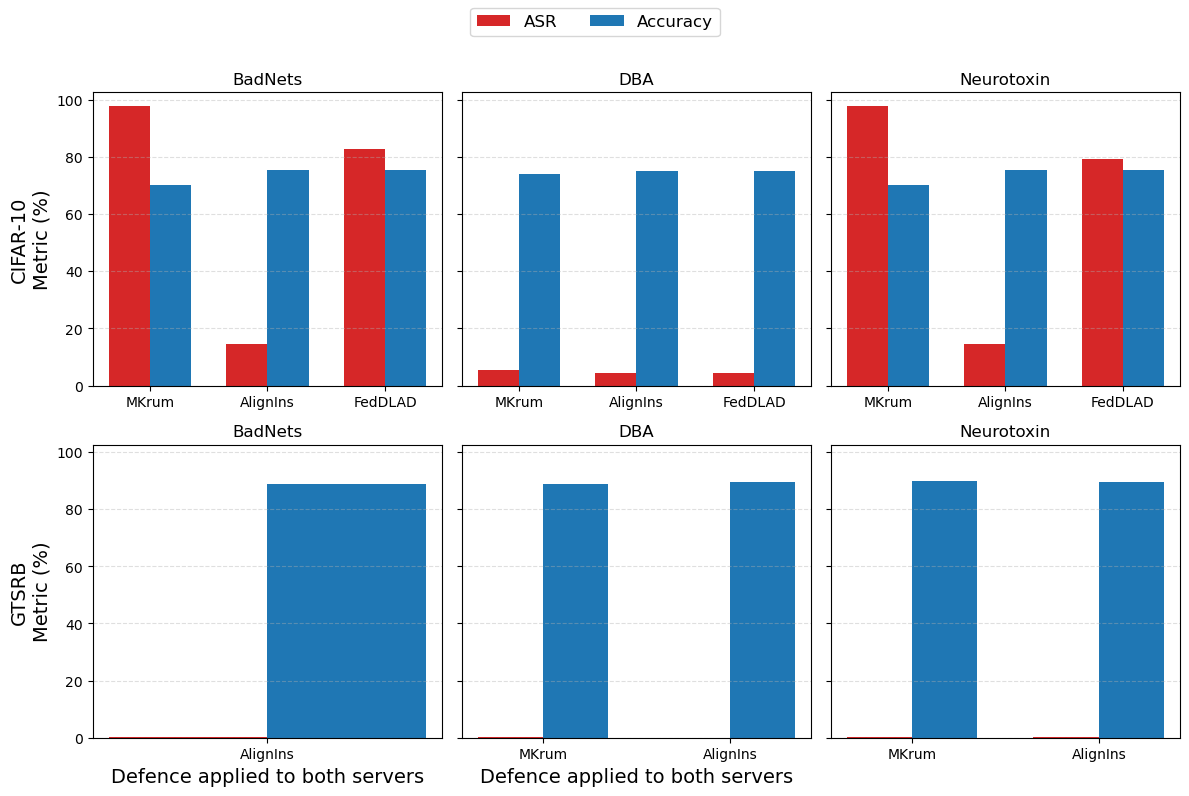

In [4]:
# Load data
# df_mnist50 = preprocess(pd.read_csv("all_start_rounds_mnist.csv"), rnd=50)
# df_mnist = preprocess(pd.read_csv("all_start_rounds_mnist.csv"), rnd=100)
# df_mnist = pd.concat([df_mnist50[df_mnist50["attack"].isin(["badnet", "neurotoxin"])], df_mnist], ignore_index=True)
df_cifar10  = preprocess(pd.read_csv("all_start_rounds_cifar10.csv"), rnd=200)
df_gtsrb  = preprocess(pd.read_csv("all_start_rounds_gtsrb.csv"), rnd=200)

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharey=True)

attacks = ["badnet", "DBA", "neurotoxin"]

# Row 0: CIFAR-10
for j, attack in enumerate(attacks):
    plot_panel(axes[0, j], df_cifar10, attack)

# Row 1: GTSRB
for j, attack in enumerate(attacks):
    plot_panel(axes[1, j], df_gtsrb, attack)

# Row labels
axes[0, 0].set_ylabel("CIFAR-10\nMetric (%)", fontsize=14)
axes[1, 0].set_ylabel("GTSRB\nMetric (%)", fontsize=14)
axes[1, 0].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1, 1].set_xlabel("Defence applied to both servers", fontsize=14)

# Shared legend (clean version)
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

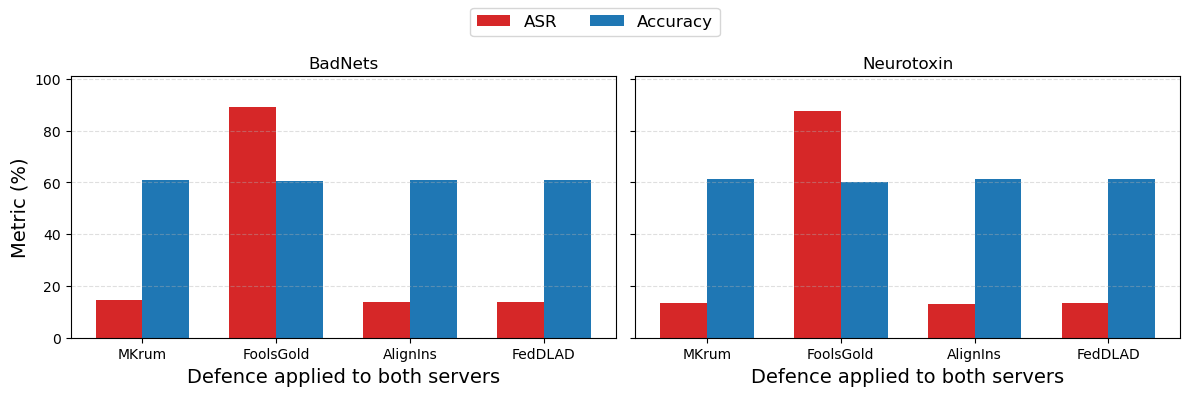

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def preprocess(df):
    df = df[df["defense"] == df["defense_server"]]
    df = df[df["defense_start_round"] == 100]
    return df

# ---- Name mappings ----
attack_map = {
    "badnet": "BadNets",
    "neurotoxin": "Neurotoxin"
}

defense_map = {
    "mkrum": "MKrum",
    "foolsgold": "FoolsGold",
    "alignins": "AlignIns",
    "feddlad": "FedDLAD",
    "avg": "FedAvg"
}
defense_order = ["mkrum", "foolsgold", "alignins", "feddlad"]

attacks = ["badnet", "neurotoxin"]

color_asr = "#d62728"   # red
color_acc = "#1f77b4"   # blue

def plot_panel(ax, df, attack):
    sub = df[df["attack"] == attack]
    grouped = sub.groupby("defense_server").mean(numeric_only=True)

    defenses = [d for d in defense_order if d in grouped.index]

    asr = [grouped.loc[d]["asr"] for d in defenses]
    acc = [grouped.loc[d]["main_task"] for d in defenses]

    x = np.arange(len(defenses))
    width = 0.35

    ax.bar(x - width/2, asr, width, color=color_asr, label="ASR")
    ax.bar(x + width/2, acc, width, color=color_acc, label="Accuracy")

    # Apply readable labels
    ax.set_title(attack_map[attack])
    ax.set_xticks(x)
    ax.set_xticklabels([defense_map.get(d, d) for d in defenses])
    ax.set_ylim(0, 101)

    # ax.set_xlabel("Defence applied to both servers", fontsize=14)
    ax.grid(axis="y", linestyle="--", alpha=0.4)


# ---- Load ONLY CIFAR-10 ----
df = preprocess(pd.read_csv("all_start_rounds_cifar10.csv"))

attacks = ["badnet", "neurotoxin"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for j, attack in enumerate(attacks):
    plot_panel(axes[j], df, attack)

axes[0].set_ylabel("Metric (%)", fontsize=14)
axes[0].set_xlabel("Defence applied to both servers", fontsize=14)
axes[1].set_xlabel("Defence applied to both servers", fontsize=14)

# shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

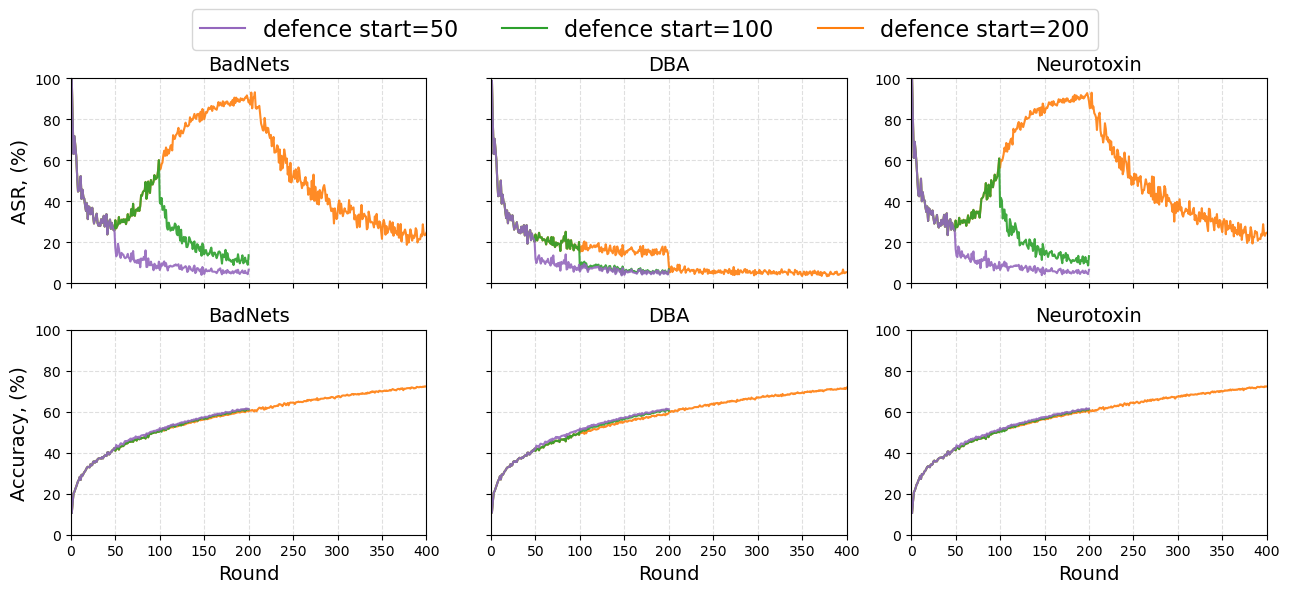

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CIFAR-10 CSV
df = pd.read_csv("all_start_rounds.csv")

df_dba_50 = df[
    (df["config_data"] == "cifar10") &
    (df["config_attack"] == "DBA") &
    (df["config_aggr"] == "avg") &
    (df["config_aggr_server"] == "alignins") &
    (df["config_defense_start_round"] ==50)
]

# Filter ONLY what you want
df = df[
    (df["config_data"] == "cifar10") &
    (df["config_aggr"] == "alignins") &
    (df["config_aggr_server"] == "alignins") &
    (df["config_defense_start_round"] <=200)
]


df = pd.concat([df, df_dba_50], ignore_index=True)

# Keep rounds <= 400
df = df[df["round"] <= 400]
attack_map = {
    "badnet": "BadNets",
    "DBA": "DBA",
    "neurotoxin": "Neurotoxin"
}
attacks = ["badnet", "DBA", "neurotoxin"]

run_ids = sorted(df["run_id"].unique())
start_rounds = sorted(df["config_defense_start_round"].unique(), reverse=True)

# reverse so smaller start rounds get "stronger / earlier" colors
colors = [
    "#ff7f0e",  # orange
    "#2ca02c",  # green
    "#9467bd",  # purple
]

color_map = dict(zip(start_rounds, colors))

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)

for i, attack in enumerate(attacks):
    sub_attack = df[df["config_attack"] == attack]

    for start in start_rounds:
        run_data = sub_attack[
            sub_attack["config_defense_start_round"] == start
        ].sort_values("round")

        if run_data.empty:
            continue

        label = f"start={start}"
        run_data["asr"] = run_data["asr"] * 100
        run_data["clean_acc"] = run_data["clean_acc"] * 100

        axes[0, i].plot(
            run_data["round"],
            run_data["asr"],
            color=color_map[start],
            alpha=0.9,
            label=label
        )

        axes[1, i].plot(
            run_data["round"],
            run_data["clean_acc"],
            color=color_map[start],
            alpha=0.9,
            label=label
        )

    axes[0, i].set_title(f"{attack_map[attack]}", fontsize=14)
    axes[1, i].set_title(f"{attack_map[attack]}", fontsize=14)

    axes[1, i].set_xlabel("Round", fontsize=14)

axes[0, 0].set_ylabel("ASR, (%)", fontsize=14)
axes[1, 0].set_ylabel("Accuracy, (%)", fontsize=14)
# formatting
for ax in axes.flat:
    ax.set_xlim(0, 400)
    ax.set_ylim(0, 100)
    ax.grid(True, linestyle="--", alpha=0.4)
for i in range(2):
    axes[0, i].tick_params(labelleft=(i == 0))
    axes[1, i].tick_params(labelleft=(i == 0))



start_rounds_legend = sorted(df["config_defense_start_round"].unique())
handles = []
labels = []

for start in start_rounds_legend:
    handles.append(plt.Line2D([0], [0], color=color_map[start]))
    labels.append(f"defence start={start}")
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.),  # move lower
    ncol=3,
    fontsize=16,
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()